# **TP1 - Times Series**

Corrigé proposé par *Groupe 4*

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.tsa.api as tsa
from scipy.stats import jarque_bera
import statsmodels.stats.diagnostic as diag
from numpy.linalg import pinv
from statsmodels.tsa.arima.model import ARIMA
from pathlib import Path
import matplotlib.pyplot as plt

## **Chargement des données**

In [2]:
path = Path("../data")

# Import Consumption data
data = pd.read_csv(path / "data.csv")

# Consider the daily consumption
data['DateTime'] = pd.to_datetime(data['DateTime'])
data = data.groupby(data['DateTime'].dt.date)['Consommation'].sum().reset_index()

# Here is the time series
Y = data['Consommation'].values

n = int(0.8 * len(Y))
train = np.arange(n)
test = np.arange(n, len(Y))


# Estimate trend and seasonality
# Propose a parametric estimation of the consumption to remove the series' trend and seasonality

## **Estimation de la tendance et de la saisonnalité**

On modélise :
$$Y_t = f(t) + \epsilon_t$$

avec $f$ périodique de période 365 :
$$f \in \{ g : \mathbb{Z} \longrightarrow \mathbb{R} \mid  \forall s \in \mathbb{Z}, \space g(s) = g(s + 365) \}$$

> Méthode 1 \
On a que $f : t \longrightarrow \beta_{t [365]}$ : 
chaque jour de l'année a son propre coefficient.


$$X = \begin{bmatrix} 1 & 0 & \dots \\ 0 & 1 & \dots \\ \vdots \\ 0 & \dots & 1\\ 1 & 0 & \dots \end{bmatrix}
\quad 
\beta = \begin{bmatrix} \beta_1 \\ \beta_2 \\ \vdots \\ \beta_{365} \end{bmatrix}
\quad
Y = \begin{bmatrix} Y_1 \\ \vdots \\ Y_{365} \\ Y_{366} \\ \vdots \end{bmatrix} $$

$$\hat{\beta} = (X^\top X)^{-1} X^\top Y$$

In [3]:
# Implémentation de la méthode 1 :

# n_days = len(Y)
# 
# X_indicator = np.zeros((n_days, 365))
# for t in range(n_days):
#     X_indicator[t, t % 365] = 1
# 
# X = pd.DataFrame(X_indicator)

> Méthode 2 \
Autrement, on peut chercher : 
$$f(t) = \alpha_0 + \alpha_1 \times cos( \frac{2\pi_t}{365}) + \alpha_2 \times sin(\frac{2\pi_t}{365})$$

C'est la méthode qu'on choisit d'implémenter : il y a moins de paramètres, donc estimation plus stable au prix d'un profil saisonnier lissé.

In [4]:
n_days = len(Y)

t = np.arange(n_days)
X = pd.DataFrame({
    'intercept': np.ones(n_days),
    'cos1': np.cos(2 * np.pi * t / 365),
    'sin1': np.sin(2 * np.pi * t / 365)
})

On estime $\hat{\beta} = (X^\top X)^{-1} X^\top Y$ sur le train set, puis on prédit sur le test set.

## **Estimation par MCO**

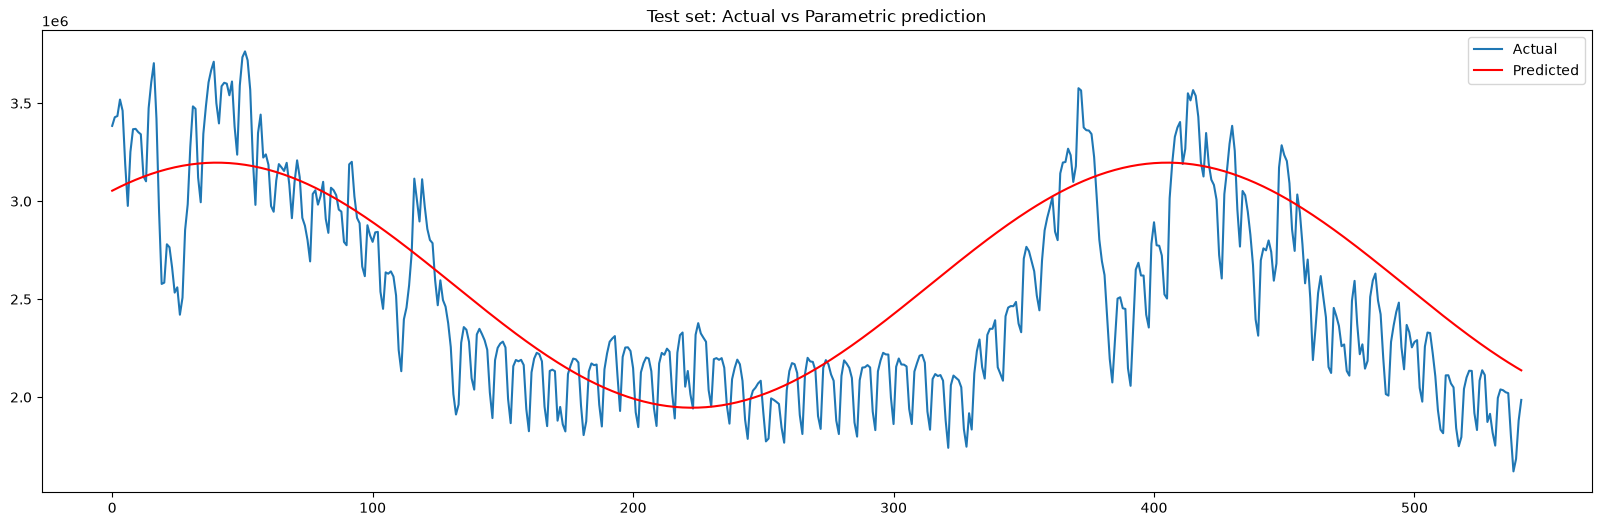

In [5]:
Y_train = Y[train]
Y_test  = Y[test]
X_train = np.matrix(X.loc[train].values)
X_test  = np.matrix(X.loc[test].values)

param = pinv( X_train.transpose() @ X_train) @ X_train.transpose() @Y_train

prev =  np.squeeze(np.asarray(X_test @ pinv( X_train.transpose() @ X_train) @ X_train.transpose() @Y_train))

plt.figure(figsize=(20, 6))
plt.plot(Y_test, label='Actual')
plt.plot(prev, label='Predicted', color='red')
plt.title('Test set: Actual vs Parametric prediction')
plt.legend()
plt.show()

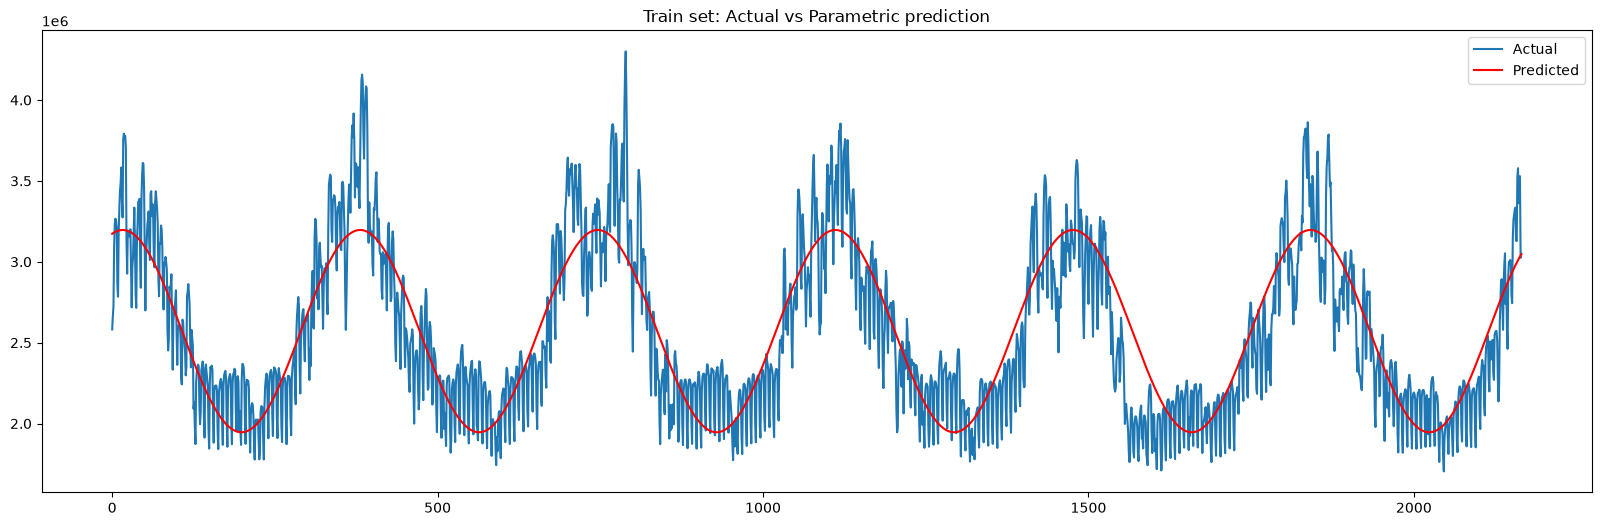

In [6]:
prev_est = np.squeeze(np.asarray(X_train @ pinv( X_train.transpose() @ X_train) @ X_train.transpose() @Y_train))

plt.figure(figsize=(20, 6))
plt.plot(Y_train, label='Actual')
plt.plot(prev_est, label='Predicted', color='red')
plt.title('Train set: Actual vs Parametric prediction')
plt.legend()
plt.show()

## **Evaluation par MAPE**

On compare la MAPE du modèle à un benchmark naïf de prédiction = moyenne du train.

In [7]:
# Define a function to calculate MAPE
def mape(y, y_hat, eps=1e-5):
    return 100 * np.mean(np.abs((y_hat - y) / (np.abs(y) + eps)))

mape_train_bch = mape(np.repeat(Y_train.mean(),len(Y_train),axis = 0), Y_train)
mape_test_bch = mape(np.repeat(Y_train.mean(),len(Y_test),axis = 0), Y_test)

print(f'The benchmark MAPE in estimation is {mape_train_bch:.2f}%')
print(f'The benchmark MAPE in prediction is {mape_test_bch:.2f}%')



mape_train = mape(prev_est, Y_train)
mape_test = mape(prev, Y_test)

print(f'The MAPE in estimation is {mape_train:.2f}%')
print(f'The MAPE in prediction is {mape_test:.2f}%')

The benchmark MAPE in estimation is 17.16%
The benchmark MAPE in prediction is 17.60%
The MAPE in estimation is 8.36%
The MAPE in prediction is 10.75%


## **Analyse du bruit résiduel**

On extrait le bruit $\epsilon_t = Y_t - \hat{f}_{t}$ et on vérifie sa stationnarité
en regardant si sa moyenne et son écart-type glissants restent stables.

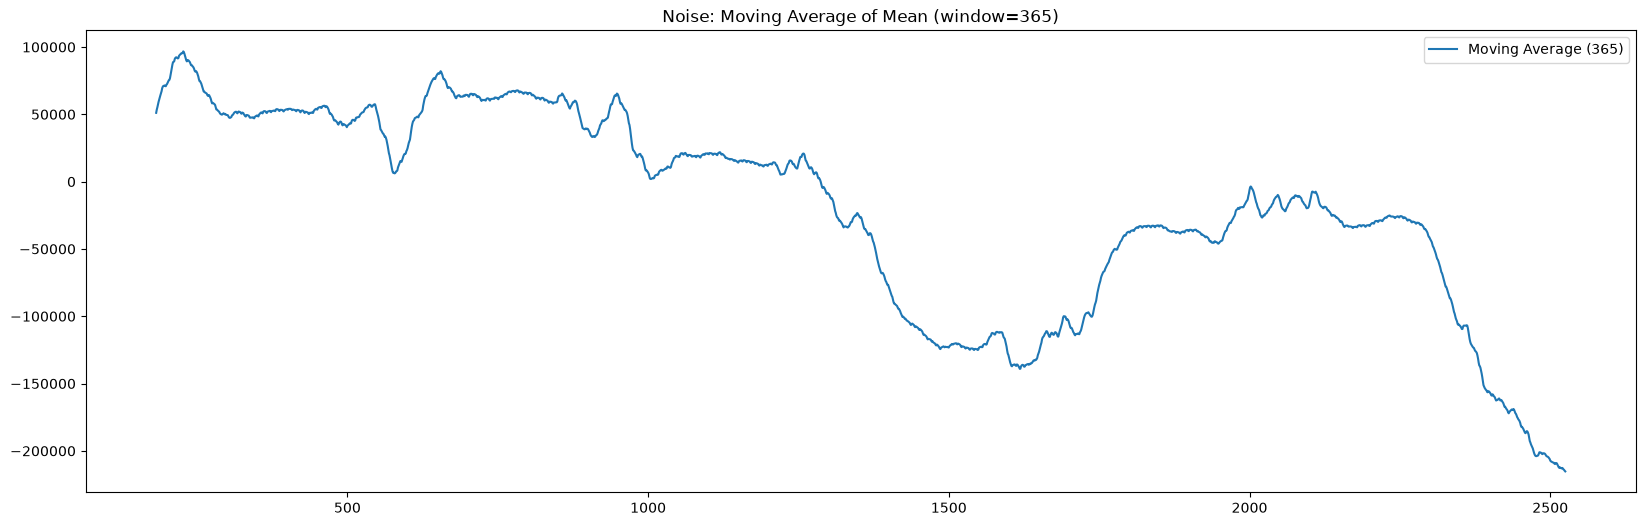

In [8]:
# Estimate noise

# Check noise stationarity
noise = np.concatenate([Y_train - prev_est, Y_test - prev])

def moving_average(y, w):
    x = pd.Series(y).rolling(window=w, center=True).mean().values
    return x

plt.figure(figsize=(20, 6))
plt.plot(moving_average(noise, 365), label='Moving Average (365)')
plt.legend()
plt.title('Noise: Moving Average of Mean (window=365)')
plt.show()

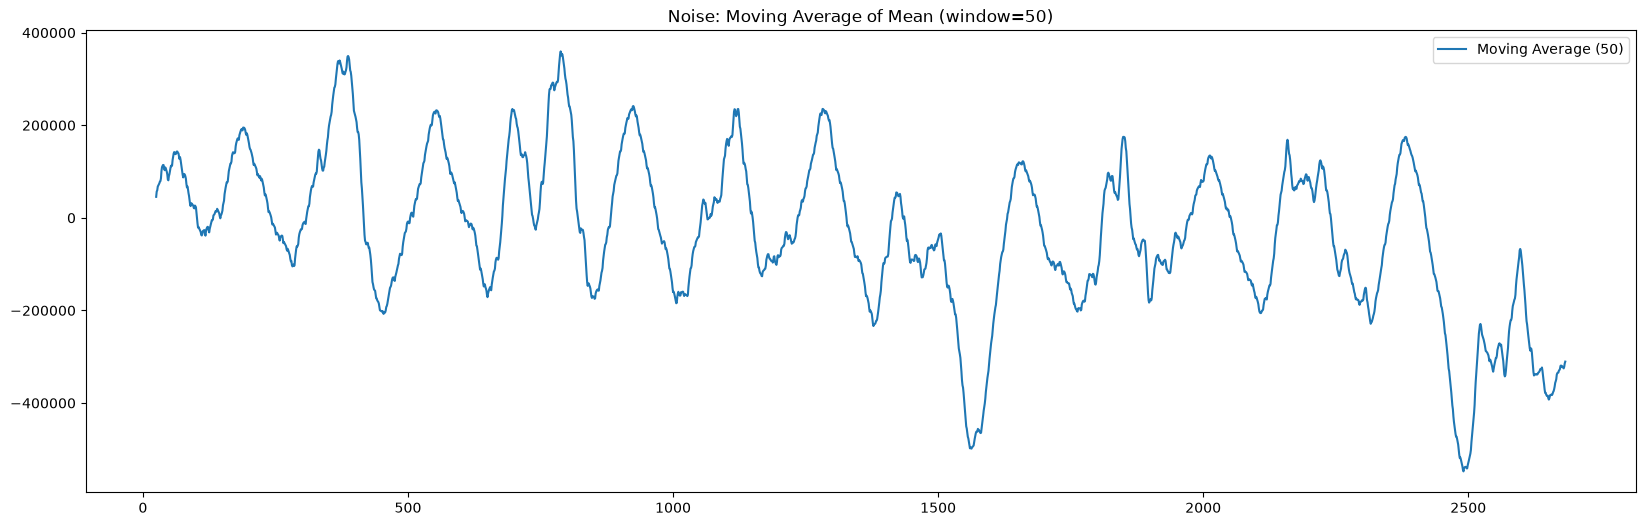

In [9]:
plt.figure(figsize=(20, 6))
plt.plot(moving_average(noise, 50), label='Moving Average (50)')
plt.legend()
plt.title('Noise: Moving Average of Mean (window=50)')
plt.show()

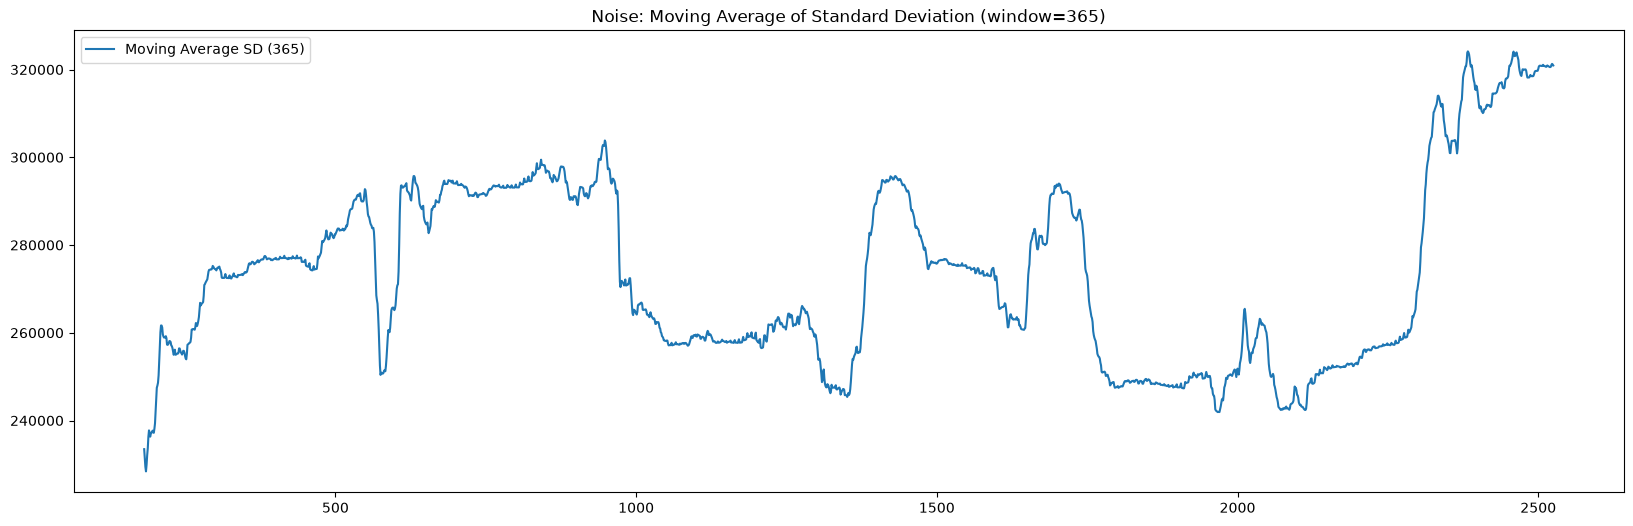

In [10]:
def moving_average_sd(y, w):
    x = pd.Series(y).rolling(window=w, center=True).std().values
    return x

plt.figure(figsize=(20, 6))
plt.plot(moving_average_sd(noise, 365), label='Moving Average SD (365)')
plt.legend()
plt.title('Noise: Moving Average of Standard Deviation (window=365)')
plt.show()

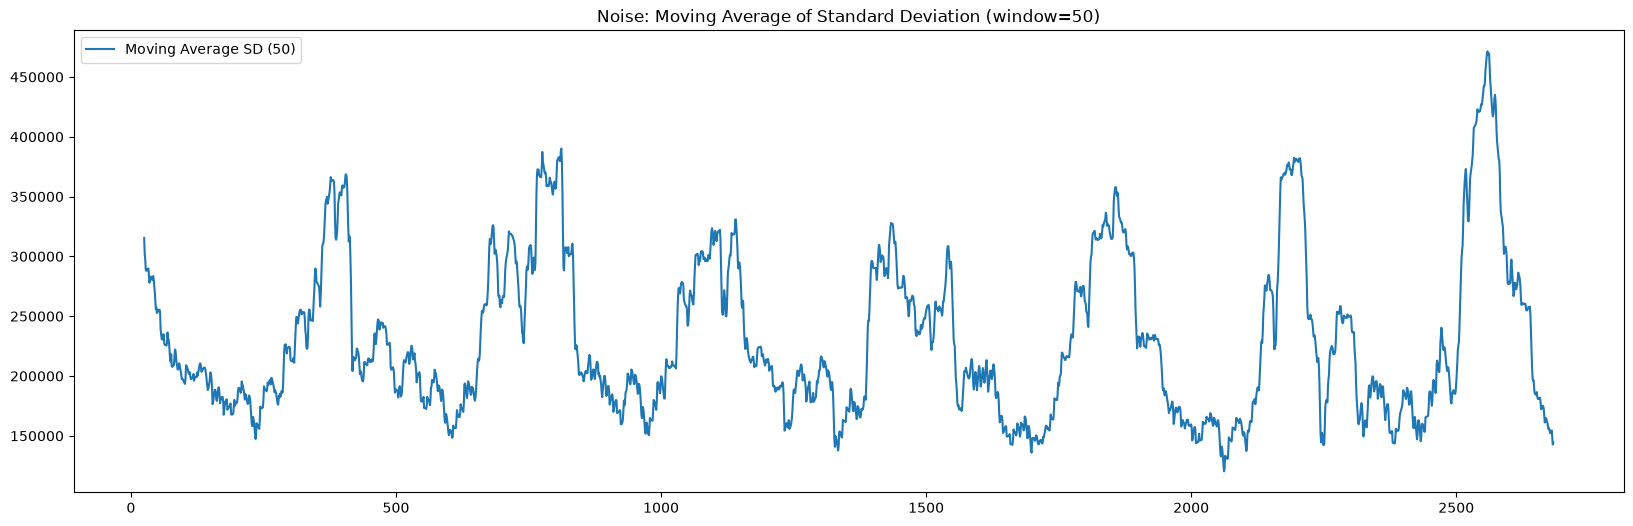

In [11]:
plt.figure(figsize=(20, 6))
plt.plot(moving_average_sd(noise, 50), label='Moving Average SD (50)')
plt.legend()
plt.title('Noise: Moving Average of Standard Deviation (window=50)')
plt.show()

## **ACF/PACF du bruit : choix du modèle ARMA**

In [12]:
# Propose an ARMA process to estimate it

acf = sm.tsa.acf(noise, nlags=50)
display(acf)

array([ 1.        ,  0.81744695,  0.58442888,  0.47375198,  0.42266469,
        0.43196177,  0.56506069,  0.66593593,  0.49258366,  0.28839235,
        0.20634672,  0.18132723,  0.21405957,  0.37241573,  0.50023676,
        0.3636682 ,  0.19416247,  0.1379129 ,  0.13295886,  0.18197535,
        0.34678226,  0.47276931,  0.33075246,  0.15207557,  0.08437238,
        0.06642505,  0.10124841,  0.2520703 ,  0.37286163,  0.23386243,
        0.06142299,  0.00636284,  0.00603786,  0.05710555,  0.22196915,
        0.35829237,  0.23381302,  0.07291296,  0.02620986,  0.02455285,
        0.06868474,  0.22453733,  0.34649838,  0.20714739,  0.03355816,
       -0.02538421, -0.03386994,  0.00545391,  0.15972924,  0.28563982,
        0.14892458])

In [13]:
pacf = sm.tsa.pacf(noise, nlags=50)
display(pacf)

array([ 1.        ,  0.81774893, -0.25311154,  0.26425074, -0.0142933 ,
        0.23973887,  0.43003024,  0.03041651, -0.62885962,  0.17464093,
        0.07025908,  0.06380041,  0.08974133,  0.16588734,  0.02812981,
       -0.25770343,  0.10361048,  0.03658875,  0.06319161,  0.0699048 ,
        0.03937904, -0.01755963, -0.22812304,  0.04356566,  0.01560167,
        0.01554677,  0.01306636,  0.02142993,  0.04730179, -0.1586135 ,
        0.04737772,  0.07660728,  0.05378251,  0.01193075,  0.02618475,
        0.05048288, -0.13780018,  0.04506285,  0.04355512, -0.03573854,
        0.01187433,  0.01702223, -0.03080416, -0.11822298,  0.04232131,
        0.01367111,  0.03249691, -0.00108173,  0.02806362,  0.02199611,
       -0.14527066])

Pour les plots, on peut utiliser directement le module `statsmodels.graphics.tsaplots` :

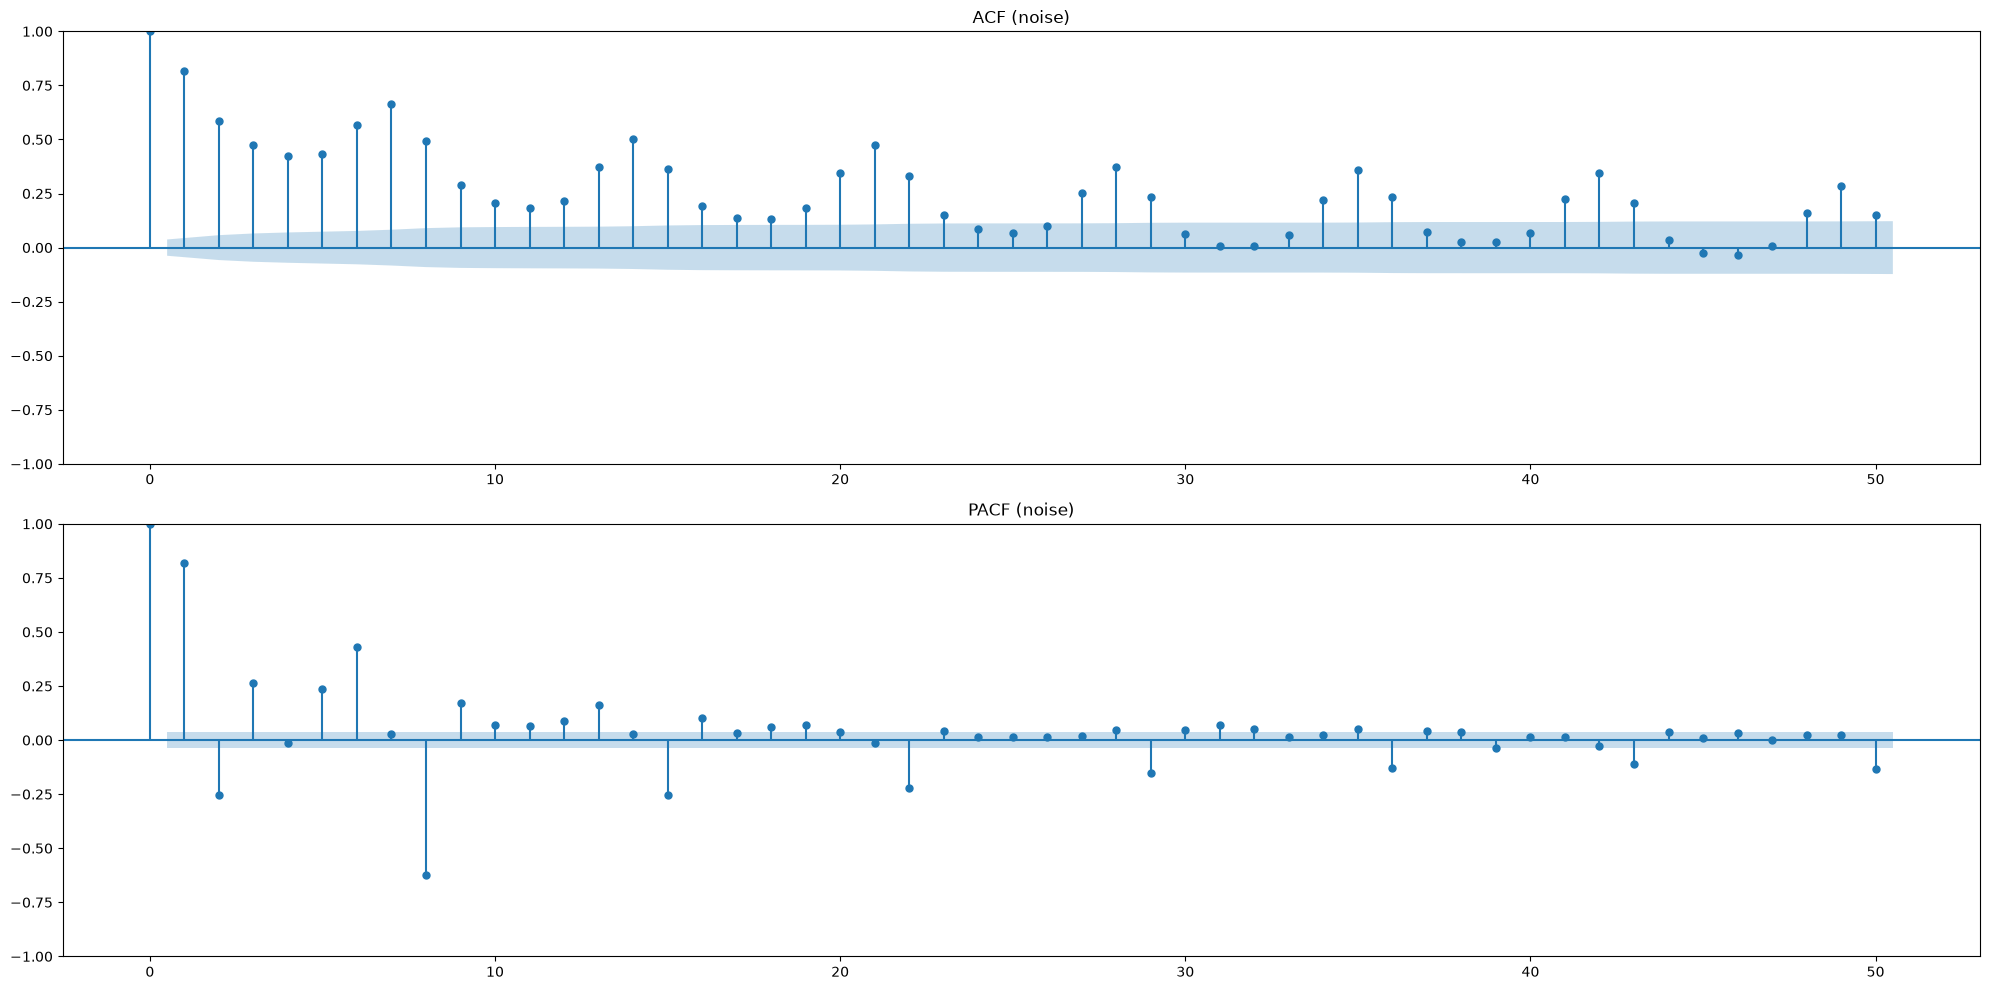

In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(20, 10))

plot_acf(noise, lags=50, ax=axes[0], title="ACF (noise)")
plot_pacf(noise, lags=50, ax=axes[1], title="PACF (noise)", method='ywm')

plt.tight_layout()
plt.show()

Ou utiliser `acf` et `pacf` calculés précédemmment :

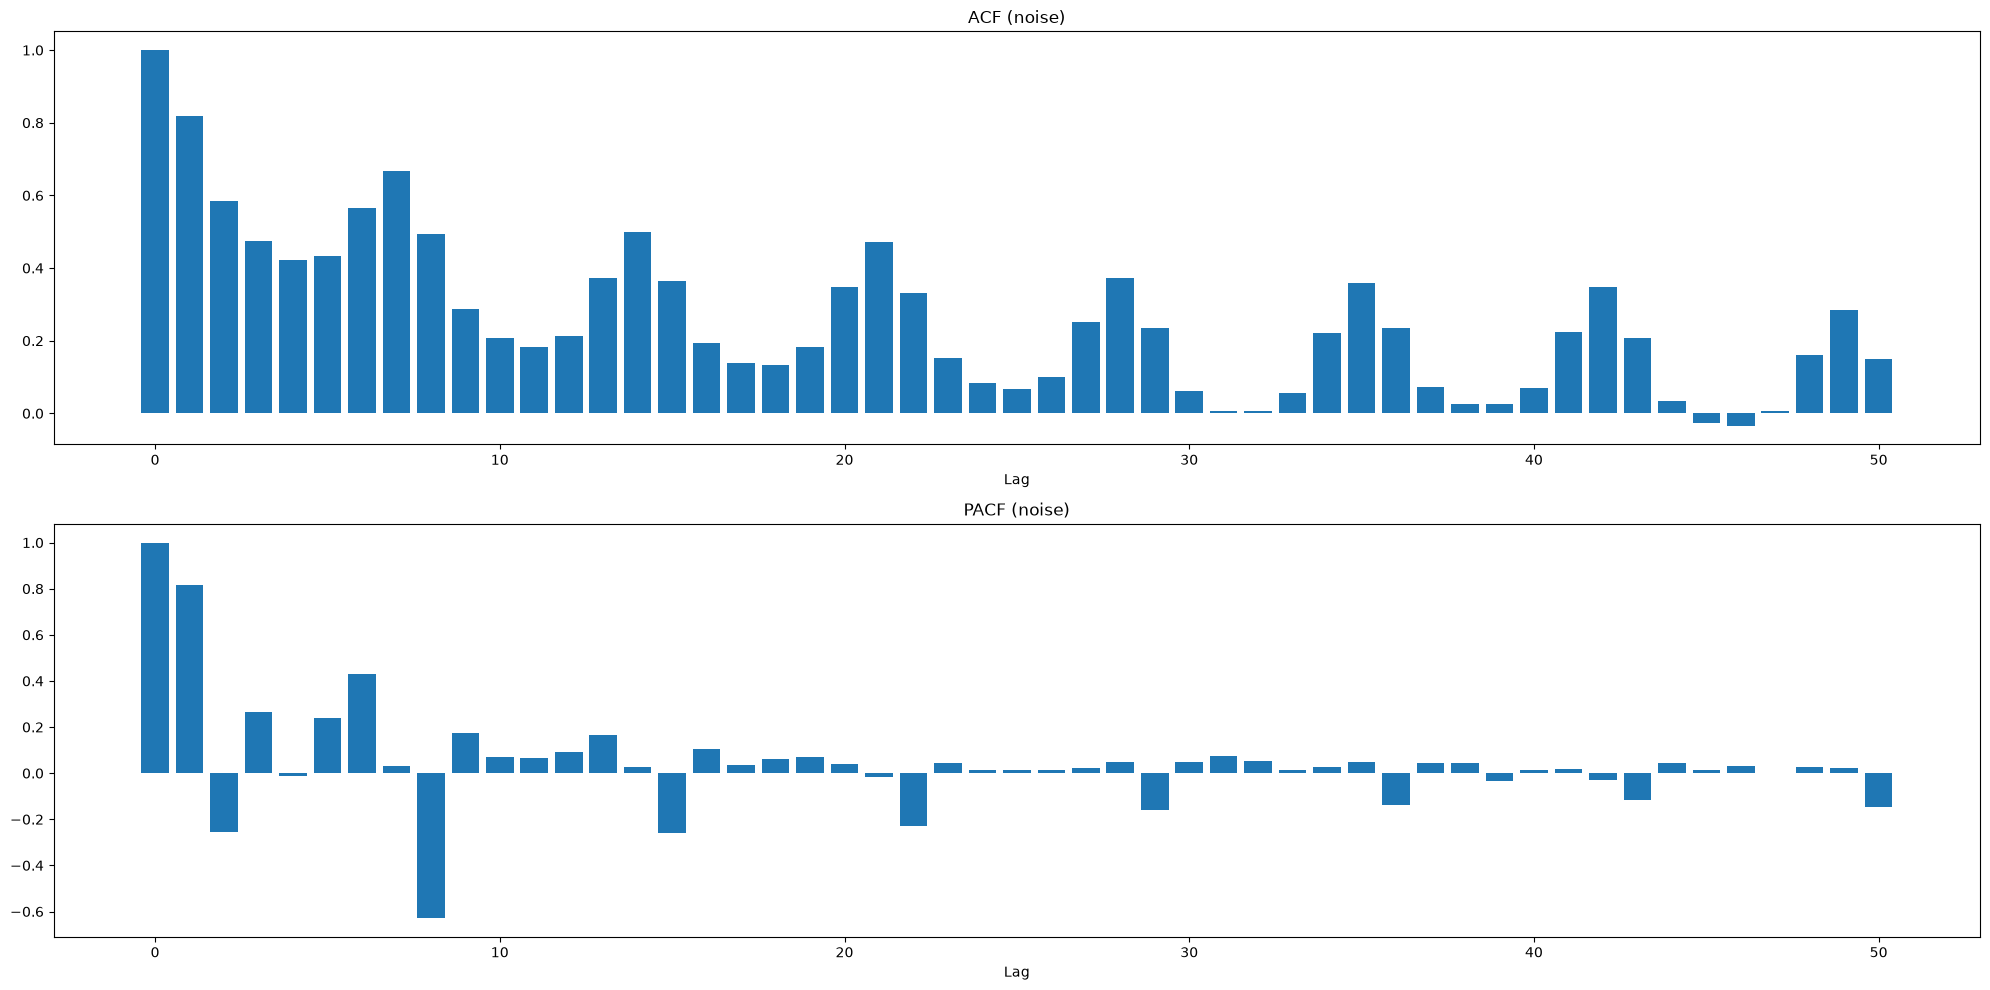

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(20, 10))

axes[0].bar(range(len(acf)), acf)
axes[0].set_title('ACF (noise)')
axes[0].set_xlabel('Lag')

axes[1].bar(range(len(pacf)), pacf)
axes[1].set_title('PACF (noise)')
axes[1].set_xlabel('Lag')

plt.tight_layout()
plt.show()

On constate que :

- L'ACF décroît lentement avec des oscillations de période $\approx$ 7 : on suggère avoir un processus AR 
- La PACF montre des lags significatifs à 1 (environ 0.8) et 7 (environ −0.6), puis tombe dans la bande de confiance, on peut parler de coupure nette à partir du lag 7

Donc on peut choisir de prendre un AR(7).

## **Modèle AR(7) : prédiction en ligne**

In [16]:
lag = 7
arma_model = ARIMA(noise[train], order=(lag, 0, 0))
arma_result = arma_model.fit()
ar_coefs = arma_result.arparams
intercept = arma_result.params[0]

# Predict the noise part based on previous values
prev_offline = np.concatenate([prev_est, prev])
prev_online = prev_offline.copy()

for t in range(lag, len(Y)):
    residuals = Y[:t] - prev_offline[:t]
    arma_t = intercept + sum(ar_coefs[i] * residuals[t - i - 1] for i in range(lag))
    prev_online[t] = prev_offline[t] + arma_t

mape_train = mape(prev_online[train], Y_train)
mape_test = mape(prev_online[test], Y_test)

print(f'The MAPE in estimation is {mape_train:.2f}%')
print(f'The MAPE in prediction is {mape_test:.2f}%')

The MAPE in estimation is 4.20%
The MAPE in prediction is 4.18%


L'ajout de la correction AR(7) améliore nettement la MAPE par rapport au modèle initial.

In [17]:
# Do predictions taking into account realistic modeling (delay of 4 days in data reception)
delay = 4
prev_online_delayed = prev_offline.copy()

for t in range(delay + lag, len(Y)):
    residuals = Y[:t - delay] - prev_offline[:t - delay]
    arma_t = intercept + sum(ar_coefs[i] * residuals[t - delay - i - 1] for i in range(lag))
    prev_online_delayed[t] = prev_offline[t] + arma_t

mape_train = mape(prev_online_delayed[train[(delay + lag):]], Y_train[(delay + lag):])
mape_test = mape(prev_online_delayed[test], Y_test)

print(f'The MAPE in estimation is {mape_train:.2f}%')
print(f'The MAPE in prediction is {mape_test:.2f}%')


The MAPE in estimation is 10.05%
The MAPE in prediction is 9.72%


La MAPE se dégrade avec le délai : les résidus utilisés datent de 4 jours, donc la correction AR est moins précise.

## **Validation des résidus**

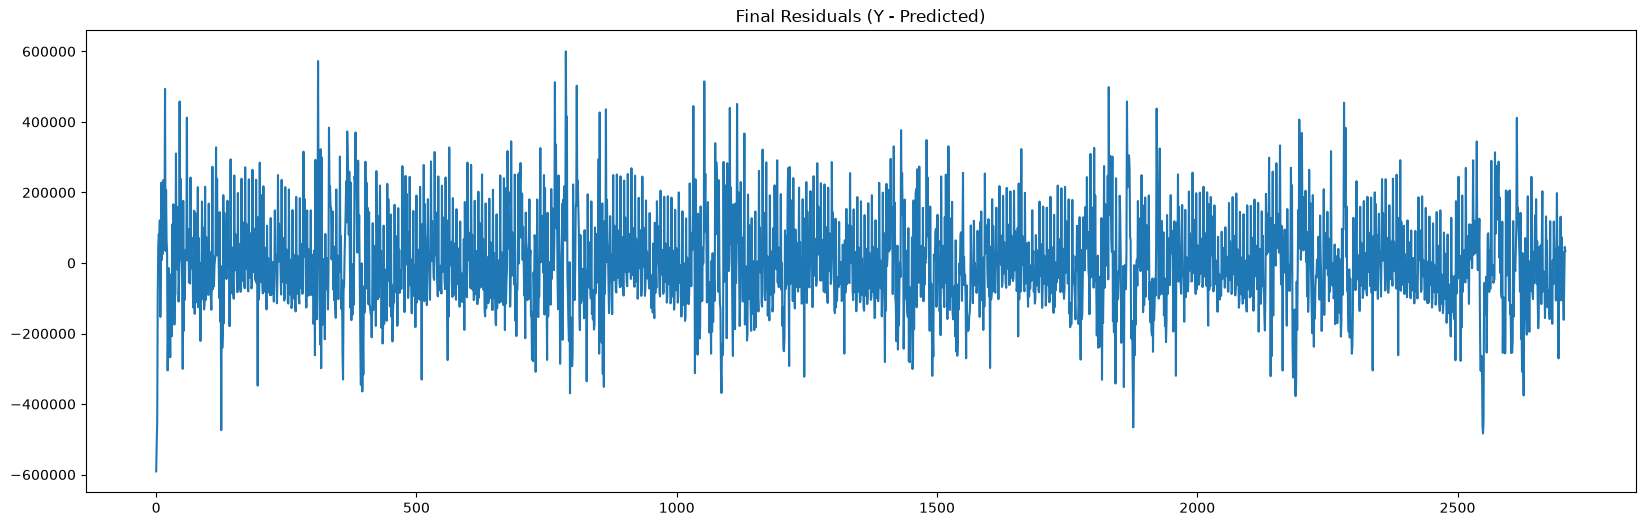

In [18]:
# Validation

# Check final residuals
Z = Y - prev_online

plt.figure(figsize=(20, 6))
plt.plot(Z)
plt.title('Final Residuals (Y - Predicted)')
plt.show()

In [19]:
# Ljung-Box Test
lb_test = diag.acorr_ljungbox(Z, lags=30, boxpierce=True)
# Jarque-Bera Test
jb_stat, jb_pval = jarque_bera(Z)

print(lb_test.head(10))
print(f'\n Jarque-Bera : stat = {jb_stat:.2f}, p-value = {jb_pval:.6f}')

        lb_stat      lb_pvalue      bp_stat      bp_pvalue
1     25.361516   4.753063e-07    25.333441   4.822748e-07
2    264.707736   3.307085e-58   264.326382   4.001800e-58
3    298.817130   1.793799e-64   298.372843   2.238352e-64
4    301.316437   5.634209e-64   300.866617   7.044750e-64
5    357.758223   3.737910e-75   357.162612   5.022092e-75
6    447.159187   2.006021e-93   446.299663   3.071250e-93
7    722.286246  1.079357e-151   720.513015  2.603490e-151
8    902.246595  1.850406e-189   899.809303  6.208715e-189
9    924.292995  3.603340e-193   921.766217  1.262514e-192
10  1004.517808  1.989273e-209  1001.635790  8.308745e-209

 Jarque-Bera : stat = 174.35, p-value = 0.000000


Le test de Ljung-Box rejette $H_0$ (p-value = 0.00 < 0.05), les résidus ne sont pas gaussiens et il reste donc de l'autocorrélation dedans.

## **Lissage exponentiel**

Approche alternative qui est non paramétrique :
$$S_t = \alpha \, S_{t-1} + (1 - \alpha) \, Y_t$$

La prédiction pour $t$ est $S_{t-1}$ (cas sans délai) ou $S_{t - \text{lag}}$ (avec délai).
On cherche le $\alpha$ optimal par grid search sur la MAPE train.

In [20]:
def exp_smooth(vec, alpha):
    n = len(vec)
    result = np.full(n, np.nan)
    result[0] = vec[0]
    for t in range(1, n):
        result[t] = alpha * result[t - 1] + (1 - alpha) * vec[t]
    return result

Alpha = np.arange(0.02, 0.99, 0.02)
Yth = np.full((len(Y_train), len(Alpha)), np.nan)
MAPES = np.full(len(Alpha), np.nan)

for i in range(len(Alpha)):
    Yth[:, i] = np.concatenate(([np.nan], exp_smooth(Y_train, Alpha[i])[:-1]))
    MAPES[i] = mape(Yth[1:, i], Y_train[1:])

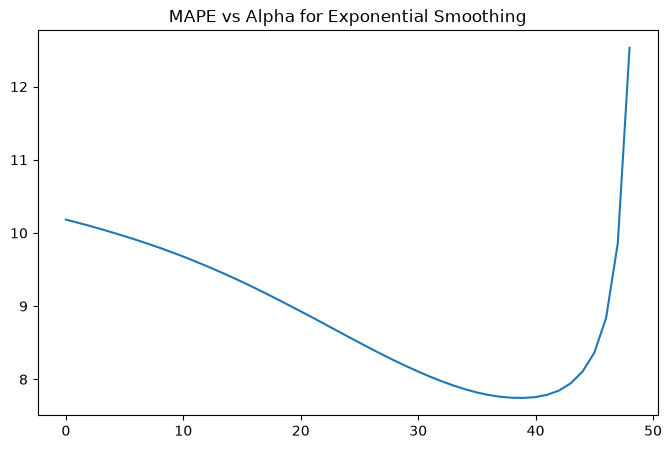

In [21]:
MAPES = np.full(len(Alpha), np.nan)
lag_exp = 4

for i in range(len(Alpha)):
    Yth[:, i] = np.concatenate((np.full(lag_exp, np.nan), exp_smooth(Y_train, Alpha[i])))[:n]
    MAPES[i] = mape(Yth[lag_exp + 1:n, i], Y_train[lag_exp + 1:n])

plt.figure(figsize=(8, 5))
plt.plot(MAPES)
plt.title('MAPE vs Alpha for Exponential Smoothing')
plt.show()

In [22]:
prev_online_sthm = np.full(len(Y), np.nan)
alpha = Alpha[np.argmin(MAPES)]
prev_online_sthm[:n] = Yth[:, np.argmin(MAPES)]

for t in range(n, len(Y)):
    prev_online_sthm[t] = alpha * prev_online_sthm[t - 1] + (1 - alpha) * Y[t - lag_exp]

mape_estimation = mape(prev_online_sthm[lag_exp + 1:n], Y_train[lag_exp + 1:n])
mape_prediction = mape(prev_online_sthm[n:], Y_test)

print(f'The MAPE in estimation is {round(mape_estimation, 2)}%.')
print(f'The MAPE in prediction is {round(mape_prediction, 2)}%.')

The MAPE in estimation is 7.75%.
The MAPE in prediction is 8.03%.
